# Pharos 03 - Anomaly detection

Two complementary views of unusual sales: a per group robust z-score that explains how far a day is from normal, and a multivariate isolation forest that flags whole days that look odd across the product mix.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
plt.rcParams.update({'figure.dpi':110,'axes.grid':True,'grid.alpha':.3,'font.size':10})
CATS=['M01AB','M01AE','N02BA','N02BE','N05B','N05C','R03','R06']
df=pd.read_csv('../data/salesdaily.csv'); df['datum']=pd.to_datetime(df['datum'],format='%m/%d/%Y')
df=df.set_index('datum').sort_index()[CATS].astype(float)

### Robust z-score
Against a 28 day rolling median, scaled by the median absolute deviation. This does not assume a symmetric or normal distribution, which matters for the skewed low count groups.

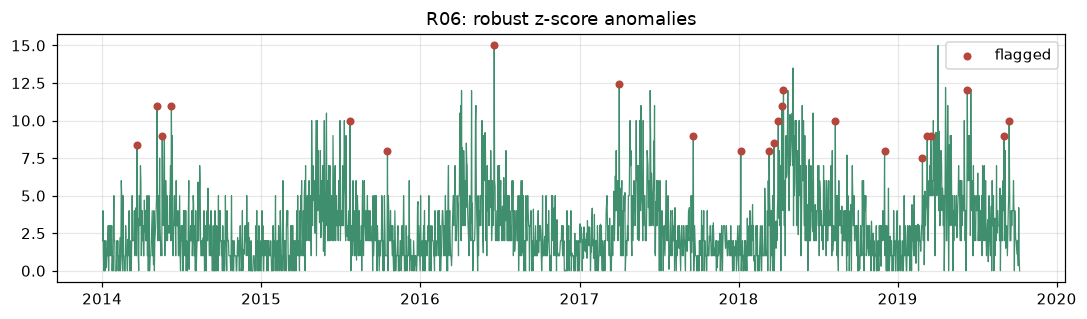

In [2]:
W=28; cat='R06'; s=df[cat]
med=s.rolling(W,min_periods=10).median()
mad=(s-med).abs().rolling(W,min_periods=10).median()
z=(s-med)/(mad*1.4826).replace(0,np.nan)
flag=z.abs()>=3.5
fig,ax=plt.subplots(figsize=(10,3))
ax.plot(s.index,s,color='#3f8e6e',lw=.8)
ax.scatter(s.index[flag.fillna(False)], s[flag.fillna(False)], color='#b4463c', s=18, zorder=3, label='flagged')
ax.legend(); ax.set_title(f'{cat}: robust z-score anomalies'); plt.tight_layout()

### Multivariate isolation forest
Over the full eight dimensional daily vector, so a day can be flagged for an unusual *combination* even if no single group is extreme.

In [3]:
Xs=StandardScaler().fit_transform(df.values)
iso=IsolationForest(n_estimators=300, contamination=0.02, random_state=42).fit(Xs)
score=iso.decision_function(Xs); flagged=iso.predict(Xs)==-1
print('flagged days:', int(flagged.sum()), 'of', len(df))
unusual=df[flagged].assign(score=score[flagged]).sort_values('score')
unusual.head(10).round(1)

flagged days: 43 of 2106


,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,score
datum,,,,,,,,,
2019-01-20,11.7,14.5,2.1,93.0,6.0,0.0,34.0,1.0,-0.1
2019-02-02,13.3,12.7,6.2,64.3,8.0,1.0,45.0,0.0,-0.1
2018-03-30,5.3,4.5,9.0,42.0,33.0,8.0,3.0,2.0,-0.1
2016-10-11,7.3,2.4,11.6,52.6,54.8,1.0,8.0,1.0,-0.1
2015-11-15,1.3,12.0,9.3,42.4,8.0,2.0,17.0,0.0,-0.0
2016-02-03,8.0,6.7,11.5,39.1,11.0,5.0,0.0,0.0,-0.0
2018-12-02,3.2,5.8,10.0,65.7,6.0,0.0,27.0,8.0,-0.0
2019-07-30,9.5,6.2,5.0,19.0,9.0,4.0,33.0,5.0,-0.0
2019-04-30,2.0,1.4,8.0,22.0,13.0,2.0,28.0,8.4,-0.0


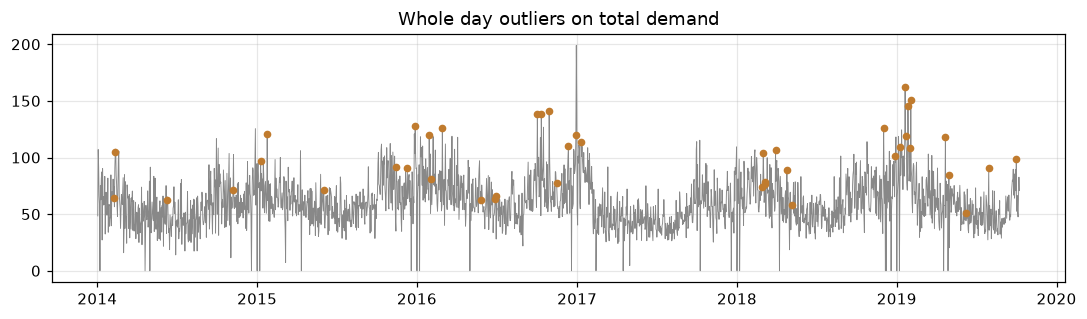

In [4]:
fig,ax=plt.subplots(figsize=(10,3))
tot=df.sum(axis=1)
ax.plot(tot.index, tot, color='#888', lw=.6)
ax.scatter(df.index[flagged], tot[flagged], color='#c07b2e', s=16, zorder=3)
ax.set_title('Whole day outliers on total demand'); plt.tight_layout()

**Reading the results.** The largest relative spikes come from R03, whose baseline is only a few units, so a seasonal surge reads as a very high z-score. These are genuine demand events worth a quick check for entry errors or local spikes, which is exactly what the Alerts queue surfaces.